# Metaheurística: algoritmo genético para optimizar una MLP

**Grupo G7 · José · oct/2026**

Se optimizan los hiperparámetros de una `MLPClassifier` con un **algoritmo genético (PyGAD)** y se compara con `RandomizedSearchCV` y con la MLP por defecto. Se usan solo los **1.827 ciclos de entrenamiento** y los cinco pliegues por `group_id` del proyecto; el conjunto de prueba no se consulta. El modelo es `crear_pipeline(MLPClassifier(...))`: el escalado y el filtro de correlación se ajustan dentro de cada pliegue.

Diseño (contrato técnico, sección 5):

- **Genes**: `hidden_layer_sizes` ∈ {(32,), (64,), (128,), (64,32), (128,64)}, `alpha` ∈ [1e-5, 1e-1] y `learning_rate_init` ∈ [1e-4, 1e-2] (ambos en escala logarítmica), `activation` ∈ {relu, tanh}. `max_iter` es fijo.
- **Aptitud**: F1 macro medio de la CV por grupos.
- **Presupuesto**: 100 evaluaciones de CV por corrida y por método.
- **Repeticiones**: 3 corridas por método con semillas 42, 43 y 44 (la semilla gobierna la búsqueda y el `random_state` de la MLP).

La selección de hiperparámetros y la evaluación de la configuración elegida usan **los mismos pliegues**, así que las cifras de CV pueden ser optimistas. La única evaluación independiente es la prueba reservada, que aquí no se toca.

In [1]:
import platform
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pygad
import sklearn
from joblib import Parallel, delayed
from scipy.stats import loguniform
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.neural_network import MLPClassifier

from ic_g7 import config
from ic_g7.datos import cargar_entrenamiento
from ic_g7.evaluacion import crear_cv, validar_cruzado
from ic_g7.pipeline import crear_pipeline

X, y, grupos = cargar_entrenamiento()
PLIEGUES = list(crear_cv().split(X, y, grupos))

print(f"Entrenamiento: {X.shape[0]} ciclos, {X.shape[1]} variables, {grupos.nunique()} grupos")
print(f"Python {platform.python_version()} · scikit-learn {sklearn.__version__} · "
      f"PyGAD {pygad.__version__} · numpy {np.__version__} · pandas {pd.__version__}")

Entrenamiento: 1827 ciclos, 68 variables, 111 grupos
Python 3.12.10 · scikit-learn 1.9.1 · PyGAD 3.9.2 · numpy 2.5.4 · pandas 3.0.6


## 1. Espacio de búsqueda y modelo

`crear_mlp` arma el pipeline con una configuración y una semilla. `evaluar_aptitud` es la función objetivo: se llama a `cross_validate` directamente, sobre los pliegues del contrato, y con `random_state` fijo en la MLP, de modo que un mismo individuo siempre recibe la misma aptitud.

In [2]:
CAPAS = [(32,), (64,), (128,), (64, 32), (128, 64)]
ACTIVACIONES = ["relu", "tanh"]
SEMILLAS = (42, 43, 44)
N_EVALUACIONES = 100


def crear_mlp(hidden_layer_sizes, alpha, learning_rate_init, activation, max_iter, semilla):
    return crear_pipeline(MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes, alpha=alpha,
        learning_rate_init=learning_rate_init, activation=activation,
        max_iter=max_iter, random_state=semilla,
    ))


def decodificar(genes):
    # los genes 1 y 2 son el exponente en base 10 (escala logaritmica)
    return {
        "hidden_layer_sizes": CAPAS[int(genes[0])],
        "alpha": float(10 ** genes[1]),
        "learning_rate_init": float(10 ** genes[2]),
        "activation": ACTIVACIONES[int(genes[3])],
    }


def evaluar_aptitud(params, semilla):
    modelo = crear_mlp(**params, max_iter=MAX_ITER, semilla=semilla)
    res = cross_validate(modelo, X, y, groups=grupos, cv=PLIEGUES,
                         scoring="f1_macro", n_jobs=1)
    return float(res["test_score"].mean())

## 2. Elección de `max_iter`

Si `max_iter` es corto, las configuraciones lentas (por ejemplo `learning_rate_init` pequeño) se cortan antes de converger y emiten `ConvergenceWarning`; entonces el GA premiaría configuraciones que solo entrenan más rápido, no las mejores. Se busca un valor con el que no haya avisos en las configuraciones extremas del espacio y, después, se verifica en las configuraciones que realmente se evalúan en cada corrida.

Se evalúan las **esquinas del espacio**: las 5 arquitecturas × `alpha` en {1e-5, 1e-1} × `learning_rate_init` en {1e-4, 1e-2} × 2 activaciones (40 configuraciones). Se prueba primero `max_iter=1000` (solo semilla 42 y `learning_rate_init=1e-4`, el caso más lento) y luego `max_iter=4000` con las tres semillas. Este sondeo usa joblib en paralelo solo para ahorrar tiempo; cada ajuste es independiente y determinista.

In [3]:
def probar_esquina(capas, alpha, lr, activacion, semilla, max_iter):
    modelo = crear_mlp(capas, alpha, lr, activacion, max_iter, semilla)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        res = cross_validate(modelo, X, y, groups=grupos, cv=PLIEGUES,
                             scoring="f1_macro", return_estimator=True, n_jobs=1)
    return {
        "max_iter": max_iter, "capas": capas, "alpha": alpha, "lr": lr,
        "activacion": activacion, "semilla": semilla,
        "iter_max_pliegue": max(e.named_steps["modelo"].n_iter_ for e in res["estimator"]),
        "avisos": sum(issubclass(a.category, ConvergenceWarning) for a in avisos),
    }


esquinas = [(c, a, lr, act) for c in CAPAS for a in (1e-5, 1e-1)
            for lr in (1e-4, 1e-2) for act in ACTIVACIONES]
tareas = [(*e, 42, 1000) for e in esquinas if e[2] == 1e-4]
tareas += [(*e, s, 4000) for e in esquinas for s in SEMILLAS]

inicio = time.perf_counter()
sondeo = pd.DataFrame(Parallel(n_jobs=6)(delayed(probar_esquina)(*t) for t in tareas))
print(f"Sondeo terminado en {(time.perf_counter() - inicio) / 60:.1f} min")

resumen_sondeo = (
    sondeo.groupby(["max_iter", "lr"])
    .agg(pruebas=("avisos", "size"), con_aviso=("avisos", lambda a: int((a > 0).sum())),
         iter_max=("iter_max_pliegue", "max"))
)
display(resumen_sondeo)

Sondeo terminado en 12.8 min


pruebas  con_aviso  iter_max
max_iter lr                                  
1000     0.0001       20         20      1000
4000     0.0001       60          0      2859
         0.0100       60          0       254

In [4]:
MAX_ITER = 4000
sondeo_final = sondeo[sondeo["max_iter"] == MAX_ITER]
assert (sondeo_final["avisos"] == 0).all(), "hay configuraciones que no convergen con MAX_ITER"
print(f"max_iter = {MAX_ITER}: sin avisos en {len(sondeo_final)} pruebas; "
      f"maximo de iteraciones usado = {sondeo_final['iter_max_pliegue'].max()} "
      f"(margen x{MAX_ITER / sondeo_final['iter_max_pliegue'].max():.2f})")

max_iter = 4000: sin avisos en 120 pruebas; maximo de iteraciones usado = 2859 (margen x1.40)


Con `max_iter=1000` el aviso aparece en las configuraciones con `learning_rate_init=1e-4` (la tabla lo muestra); con `max_iter=4000` no hay avisos en ninguna esquina y queda margen sobre el máximo observado. Se fija **`max_iter = 4000`** para los tres métodos (también para la MLP por defecto, cuyo `max_iter=200` estándar no converge). **Alcance del sondeo**: solo prueba las esquinas del espacio; no demuestra convergencia en todos los puntos de un espacio continuo. Por eso la verificación que sí cubre las configuraciones realmente evaluadas es otra: cada corrida cuenta los `ConvergenceWarning` que aparecen en todas sus evaluaciones (100 de búsqueda más las 5 de `validar_cruzado`) y debe ser cero (sección 4).

## 3. Los tres métodos

Cada función devuelve la mejor configuración, su aptitud de búsqueda, el número de evaluaciones y la secuencia de aptitudes.

- **GA**: población de 10, 9 generaciones, `keep_elitism=0` y `keep_parents=0`. PyGAD no reevalúa a los padres que conserva, así que con estos valores cada generación evalúa 10 individuos nuevos: 10 (población inicial) + 9 × 10 = **100 llamadas a la aptitud**. Las llamadas se cuentan dentro de la función de aptitud. Sin élite, el mejor individuo de la última generación puede ser peor que uno anterior, por lo que la mejor configuración se toma entre **todas** las evaluadas (igual que hace `RandomizedSearchCV`).
- **`RandomizedSearchCV`**: `n_iter=100` sobre el mismo espacio (misma distribución logarítmica) y el mismo pipeline, con `refit=False`.
- **MLP por defecto**: hiperparámetros por defecto de scikit-learn salvo `max_iter` y `random_state`.

In [5]:
def correr_ga(semilla):
    historial = []  # (params, aptitud) en orden de evaluacion

    def aptitud(ga, solucion, indice):
        params = decodificar(solucion)
        valor = evaluar_aptitud(params, semilla)
        historial.append((params, valor))
        return valor

    ga = pygad.GA(
        num_generations=9, num_parents_mating=4, fitness_func=aptitud,
        sol_per_pop=10, num_genes=4,
        gene_space=[[0, 1, 2, 3, 4], {"low": -5, "high": -1}, {"low": -4, "high": -2}, [0, 1]],
        gene_type=[int, float, float, int],
        parent_selection_type="sss", crossover_type="single_point",
        mutation_type="random", mutation_num_genes=1,
        keep_elitism=0, keep_parents=0,
        random_seed=semilla, suppress_warnings=True,
    )
    ga.run()
    aptitudes = [valor for _, valor in historial]
    mejor = int(np.argmax(aptitudes))
    return {
        "params": historial[mejor][0], "f1_busqueda": aptitudes[mejor],
        "n_evaluaciones": len(historial), "aptitudes": aptitudes,
    }


ESPACIO_RS = {
    "modelo__hidden_layer_sizes": CAPAS,
    "modelo__alpha": loguniform(1e-5, 1e-1),
    "modelo__learning_rate_init": loguniform(1e-4, 1e-2),
    "modelo__activation": ACTIVACIONES,
}


def correr_busqueda_aleatoria(semilla):
    busqueda = RandomizedSearchCV(
        crear_pipeline(MLPClassifier(max_iter=MAX_ITER, random_state=semilla)),
        ESPACIO_RS, n_iter=N_EVALUACIONES, scoring="f1_macro", cv=crear_cv(),
        n_jobs=1, refit=False, random_state=semilla,
    )
    busqueda.fit(X, y, groups=grupos)
    params = {k.removeprefix("modelo__"): v for k, v in busqueda.best_params_.items()}
    params["alpha"] = float(params["alpha"])
    params["learning_rate_init"] = float(params["learning_rate_init"])
    return {
        "params": params, "f1_busqueda": float(busqueda.best_score_),
        "n_evaluaciones": len(busqueda.cv_results_["params"]),
        "aptitudes": [float(v) for v in busqueda.cv_results_["mean_test_score"]],
    }


def correr_defecto(semilla):
    base = MLPClassifier().get_params()
    params = {k: base[k] for k in ("hidden_layer_sizes", "alpha", "learning_rate_init", "activation")}
    return {"params": params, "f1_busqueda": None, "n_evaluaciones": 0, "aptitudes": []}

`correr_semilla` ejecuta los tres métodos para una semilla y evalúa cada configuración elegida con `validar_cruzado`, que devuelve la fila de la tabla de resultados y los valores por pliegue. Cuenta los `ConvergenceWarning` de todo lo que ocurre dentro de cada método. Las tres semillas se reparten en tres procesos (cada una es independiente y determinista); más abajo se comprueba que esto no cambia los resultados.

In [6]:
def correr_semilla(semilla):
    salida = {"semilla": semilla, "filas": [], "pliegues": [], "metodos": {}}
    ejecuciones = [
        ("MLP defecto", correr_defecto),
        ("MLP+RandomizedSearchCV", correr_busqueda_aleatoria),
        ("MLP+GA", correr_ga),
    ]
    for etiqueta, funcion in ejecuciones:
        nombre = f"{etiqueta} (semilla {semilla})"
        inicio = time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            r = funcion(semilla)
            hiperparametros = {**r["params"], "max_iter": MAX_ITER, "random_state": semilla}
            modelo = crear_mlp(**r["params"], max_iter=MAX_ITER, semilla=semilla)
            fila, por_pliegue = validar_cruzado(modelo, X, y, grupos, nombre, hiperparametros)
        r["avisos_convergencia"] = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
        r["otros_avisos"] = sorted({str(a.message)[:80] for a in avisos
                                    if not issubclass(a.category, ConvergenceWarning)})
        r["segundos"] = time.perf_counter() - inicio
        r["f1_cv"] = float(por_pliegue["f1_macro"].mean())
        salida["filas"].append(fila)
        salida["pliegues"].append(por_pliegue.assign(modelo=nombre))
        salida["metodos"][etiqueta] = r
    return salida

## 4. Ejecución

Tres corridas por método con las semillas 42, 43 y 44. Con el presupuesto de 100 evaluaciones, el tiempo total depende de cuántas configuraciones lentas aparezcan; es normal que tarde decenas de minutos.

In [7]:
inicio = time.perf_counter()
corridas = Parallel(n_jobs=len(SEMILLAS))(delayed(correr_semilla)(s) for s in SEMILLAS)
print(f"Terminado en {(time.perf_counter() - inicio) / 60:.1f} min")

Terminado en 73.4 min


### Presupuesto y convergencia

Cada corrida de GA y de búsqueda aleatoria debe tener exactamente 100 evaluaciones y ningún `ConvergenceWarning`. Las dos últimas columnas comparan la aptitud de búsqueda con el F1 macro que reporta `validar_cruzado` para la misma configuración (deben coincidir, porque usan los mismos pliegues y la misma semilla).

In [8]:
control = []
for c in corridas:
    for etiqueta, r in c["metodos"].items():
        control.append({
            "metodo": etiqueta, "semilla": c["semilla"],
            "evaluaciones": r["n_evaluaciones"],
            "avisos_convergencia": r["avisos_convergencia"],
            "otros_avisos": "; ".join(r["otros_avisos"]) or "-",
            "f1_busqueda": r["f1_busqueda"], "f1_validar_cruzado": r["f1_cv"],
            "minutos": round(r["segundos"] / 60, 1),
        })
control = pd.DataFrame(control)
display(control)

busquedas = control[control["metodo"] != "MLP defecto"]
assert (busquedas["evaluaciones"] == N_EVALUACIONES).all(), "alguna corrida no uso 100 evaluaciones"
assert (control["avisos_convergencia"] == 0).all(), "hay avisos de convergencia"
assert np.allclose(busquedas["f1_busqueda"].astype(float), busquedas["f1_validar_cruzado"], atol=1e-9)
print("OK: 100 evaluaciones por corrida, sin avisos de convergencia, aptitud = F1 de validar_cruzado")

,metodo,semilla,evaluaciones,avisos_convergencia,otros_avisos,f1_busqueda,f1_validar_cruzado,minutos
0,MLP defecto,42,0,0,-,NaN,0.724948,0.2
1,MLP+RandomizedSearchCV,42,100,0,-,0.808001,0.808001,35.5
2,MLP+GA,42,100,0,-,0.812303,0.812303,27.6
3,MLP defecto,43,0,0,-,NaN,0.720670,0.2
4,MLP+RandomizedSearchCV,43,100,0,-,0.806503,0.806503,30.6
5,MLP+GA,43,100,0,-,0.803857,0.803857,38.0
6,MLP defecto,44,0,0,-,NaN,0.730517,0.2
7,MLP+RandomizedSearchCV,44,100,0,-,0.803836,0.803836,28.7
8,MLP+GA,44,100,0,-,0.811815,0.811815,44.4


OK: 100 evaluaciones por corrida, sin avisos de convergencia, aptitud = F1 de validar_cruzado


### Comprobación: el paralelo por semilla no cambia los resultados

Se reevalúa en este proceso (secuencial) la mejor configuración del GA y de la búsqueda aleatoria con semilla 42; la aptitud debe coincidir con la obtenida dentro de los procesos paralelos.

In [9]:
for etiqueta in ("MLP+GA", "MLP+RandomizedSearchCV"):
    r = corridas[0]["metodos"][etiqueta]
    secuencial = evaluar_aptitud(r["params"], 42)
    print(f"{etiqueta}: paralelo {r['f1_busqueda']:.12f} · secuencial {secuencial:.12f}")
    assert abs(secuencial - r["f1_busqueda"]) < 1e-9

MLP+GA: paralelo 0.812303298132 · secuencial 0.812303298132


MLP+RandomizedSearchCV: paralelo 0.808001297971 · secuencial 0.808001297971


## 5. Resultados

In [10]:
filas = [fila for c in corridas for fila in c["filas"]]
resultados = pd.DataFrame(filas)
assert resultados["modelo"].is_unique and len(resultados) == 9

pliegues = pd.concat([p for c in corridas for p in c["pliegues"]], ignore_index=True)

config.DIR_REPORTES.mkdir(exist_ok=True)
resultados.to_csv(config.DIR_REPORTES / "resultados_jose.csv", index=False)
pliegues.to_csv(config.DIR_REPORTES / "pliegues_jose.csv", index=False)
pd.set_option("display.max_colwidth", 120)
display(resultados)

,modelo,hiperparámetros,F1_macro_CV (media±std),exactitud_CV,ROC_AUC_CV,t_entrenamiento,t_inferencia
0,MLP defecto (semilla 42),"{'hidden_layer_sizes': (100,), 'alpha': 0.0001, 'learning_rate_init': 0.001, 'activation': 'relu', 'max_iter': 4000,...",0.7249 ± 0.0891,0.7259 ± 0.1277,0.9163 ± 0.0452,2.644657,0.003013
1,MLP+RandomizedSearchCV (semilla 42),"{'activation': 'tanh', 'alpha': 5.3572800696018346e-05, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.0004...",0.8080 ± 0.0767,0.8105 ± 0.0943,0.9549 ± 0.0285,4.243776,0.004923
2,MLP+GA (semilla 42),"{'hidden_layer_sizes': (64,), 'alpha': 0.0035127047262708444, 'learning_rate_init': 0.0026698666742744587, 'activati...",0.8123 ± 0.0543,0.8207 ± 0.0623,0.9551 ± 0.0252,0.780434,0.002098
3,MLP defecto (semilla 43),"{'hidden_layer_sizes': (100,), 'alpha': 0.0001, 'learning_rate_init': 0.001, 'activation': 'relu', 'max_iter': 4000,...",0.7207 ± 0.0860,0.7271 ± 0.1101,0.9139 ± 0.0422,2.594779,0.003475
4,MLP+RandomizedSearchCV (semilla 43),"{'activation': 'tanh', 'alpha': 9.235769500147751e-05, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.00093762...",0.8065 ± 0.0675,0.8200 ± 0.0733,0.9523 ± 0.0313,3.571932,0.003908
5,MLP+GA (semilla 43),"{'hidden_layer_sizes': (64,), 'alpha': 3.7836722837523075e-05, 'learning_rate_init': 0.0015448928871286732, 'activat...",0.8039 ± 0.0643,0.8138 ± 0.0702,0.9529 ± 0.0282,1.734113,0.001823
6,MLP defecto (semilla 44),"{'hidden_layer_sizes': (100,), 'alpha': 0.0001, 'learning_rate_init': 0.001, 'activation': 'relu', 'max_iter': 4000,...",0.7305 ± 0.0933,0.7283 ± 0.1327,0.9117 ± 0.0485,2.830115,0.002535
7,MLP+RandomizedSearchCV (semilla 44),"{'activation': 'tanh', 'alpha': 0.01635218806030601, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.000531...",0.8038 ± 0.0823,0.8036 ± 0.1064,0.9529 ± 0.0309,4.838357,0.005575
8,MLP+GA (semilla 44),"{'hidden_layer_sizes': (128,), 'alpha': 7.059575414803102e-05, 'learning_rate_init': 0.005186234384236341, 'activati...",0.8118 ± 0.0672,0.8284 ± 0.0752,0.9571 ± 0.0302,0.852187,0.002107


### Resumen por método

Media y variación entre las 3 corridas del F1 macro medio de CV (la desviación entre corridas usa `ddof=1`). `t_entrenamiento` es el tiempo de ajuste por pliegue de la configuración elegida, no el coste de la búsqueda (cada corrida de GA o de búsqueda aleatoria tardó entre 28 y 44 min). Las tres semillas corrieron en paralelo (3 procesos simultáneos en un equipo de 12 hilos lógicos), así que estos tiempos no son comparables con los de KNN, SVM o Random Forest sin condiciones comunes. `std CV` es la desviación entre pliegues dentro de una corrida, promediada sobre las tres. Recuerda que búsqueda y evaluación comparten pliegues: las cifras pueden ser optimistas.

In [11]:
def f1_cv(fila):
    media, desviacion = re.findall(r"[0-9.]+", fila["F1_macro_CV (media±std)"])
    return float(media), float(desviacion)


tabla = []
for etiqueta in ("MLP defecto", "MLP+RandomizedSearchCV", "MLP+GA"):
    propias = [f for f in filas if f["modelo"].startswith(etiqueta)]
    medias, desviaciones = zip(*[f1_cv(f) for f in propias])
    tabla.append({
        "metodo": etiqueta,
        "F1 macro CV (media de 3 corridas)": np.mean(medias),
        "std entre corridas": np.std(medias, ddof=1),
        "min": np.min(medias), "max": np.max(medias),
        "std CV (media de 3)": np.mean(desviaciones),
        "t_entrenamiento medio (s)": np.mean([f["t_entrenamiento"] for f in propias]),
    })
resumen = pd.DataFrame(tabla).set_index("metodo")
display(resumen.round(4))

,F1 macro CV (media de 3 corridas),std entre corridas,min,max,std CV (media de 3),t_entrenamiento medio (s)
metodo,,,,,,
MLP defecto,0.7254,0.0049,0.7207,0.7305,0.0895,2.6899
MLP+RandomizedSearchCV,0.8061,0.0021,0.8038,0.8080,0.0755,4.2180
MLP+GA,0.8093,0.0047,0.8039,0.8123,0.0619,1.1222


### Curva de convergencia

Izquierda: mejor aptitud de cada generación del GA, una línea por semilla (la generación 0 es la población inicial aleatoria). Derecha: mejor aptitud acumulada del GA (línea continua) frente a la búsqueda aleatoria (discontinua) con el mismo número de evaluaciones, agrupadas en bloques de 10.

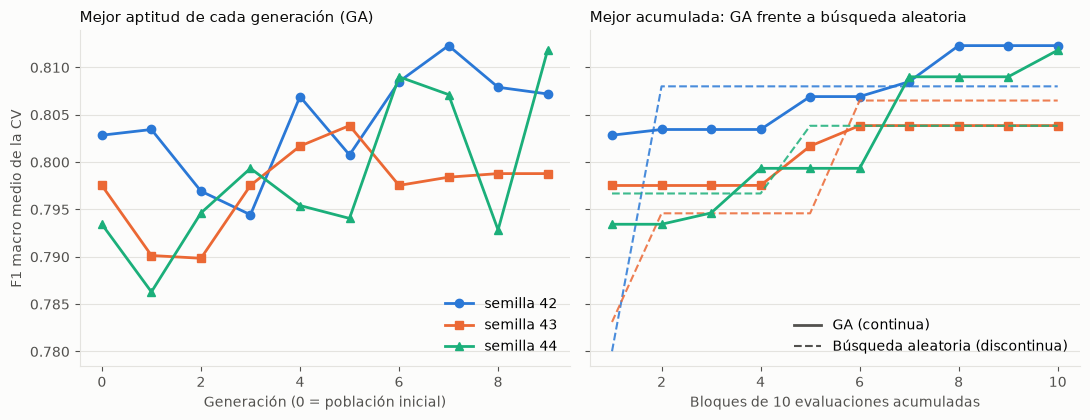

In [12]:
COLORES = {42: "#2a78d6", 43: "#eb6834", 44: "#1baf7a"}
MARCADORES = {42: "o", 43: "s", 44: "^"}
TINTA, TINTA_SEC, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
fig.patch.set_facecolor("#fcfcfb")
for c in corridas:
    s = c["semilla"]
    ga_apt = np.array(c["metodos"]["MLP+GA"]["aptitudes"]).reshape(10, 10)
    rs_apt = np.array(c["metodos"]["MLP+RandomizedSearchCV"]["aptitudes"]).reshape(10, 10)
    mejor_gen = ga_apt.max(axis=1)
    izq.plot(range(10), mejor_gen, color=COLORES[s], marker=MARCADORES[s], lw=2, ms=6,
             label=f"semilla {s}")
    der.plot(range(1, 11), np.maximum.accumulate(mejor_gen), color=COLORES[s],
             marker=MARCADORES[s], lw=2, ms=6)
    der.plot(range(1, 11), np.maximum.accumulate(rs_apt.max(axis=1)), color=COLORES[s],
             ls="--", lw=1.5, alpha=0.85)

izq.set_title("Mejor aptitud de cada generación (GA)", color=TINTA, fontsize=11, loc="left")
izq.set_xlabel("Generación (0 = población inicial)", color=TINTA_SEC)
der.set_title("Mejor acumulada: GA frente a búsqueda aleatoria", color=TINTA, fontsize=11, loc="left")
der.set_xlabel("Bloques de 10 evaluaciones acumuladas", color=TINTA_SEC)
izq.set_ylabel("F1 macro medio de la CV", color=TINTA_SEC)
izq.legend(frameon=False, loc="lower right")
der.plot([], [], color=TINTA_SEC, lw=2, label="GA (continua)")
der.plot([], [], color=TINTA_SEC, lw=1.5, ls="--", label="Búsqueda aleatoria (discontinua)")
der.legend(frameon=False, loc="lower right")
for ax in (izq, der):
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="y", color=GRILLA, lw=0.8)
    ax.tick_params(colors=TINTA_SEC)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(GRILLA)
fig.tight_layout()
(config.DIR_REPORTES / "figuras").mkdir(exist_ok=True)
fig.savefig(config.DIR_REPORTES / "figuras" / "convergencia_ga_jose.png", dpi=150,
            facecolor=fig.get_facecolor())
plt.show()

## 6. Métricas por clase y matriz de confusión

El contrato (sección 6) pide precisión, recall y F1 por clase y la matriz de confusión de cada modelo. Se calculan para las **9 configuraciones seleccionadas** (las filas de `resultados_jose.csv`, sin repetir ninguna búsqueda) con **predicciones fuera de pliegue sobre el entrenamiento**: la misma CV por grupos, cada ciclo se predice con un modelo que no lo vio. El conjunto de prueba no interviene.

Control: el F1 macro medio por pliegue recalculado con estas predicciones debe coincidir con el de la tabla de resultados. Las métricas por clase usan las predicciones de los 1.827 ciclos juntas (no promedian pliegues).

In [14]:
import ast

from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import cross_val_predict

BAR_POR_CLASE = {clase: bar for bar, clase in config.CLASE_POR_OBJETIVO.items()}
CLASES = sorted(BAR_POR_CLASE)
resultados_csv = pd.read_csv(config.DIR_REPORTES / "resultados_jose.csv")

filas_clase, filas_matriz, control_oof = [], [], []
for _, fila in resultados_csv.iterrows():
    params = ast.literal_eval(fila["hiperparámetros"])
    semilla, max_iter = params.pop("random_state"), params.pop("max_iter")
    modelo = crear_mlp(**params, max_iter=max_iter, semilla=semilla)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        prediccion = cross_val_predict(modelo, X, y, groups=grupos, cv=PLIEGUES, n_jobs=1)

    f1_pliegues = np.mean([f1_score(y.iloc[v], prediccion[v], average="macro") for _, v in PLIEGUES])
    f1_tabla = float(fila["F1_macro_CV (media±std)"].split()[0])
    assert abs(f1_pliegues - f1_tabla) < 6e-5, (fila["modelo"], f1_pliegues, f1_tabla)
    control_oof.append({"modelo": fila["modelo"], "f1_macro_pliegues": f1_pliegues,
                        "f1_macro_tabla": f1_tabla,
                        "avisos_convergencia": sum(issubclass(a.category, ConvergenceWarning) for a in avisos)})

    precision, recall, f1, soporte = precision_recall_fscore_support(
        y, prediccion, labels=CLASES, zero_division=0)
    for i, clase in enumerate(CLASES):
        filas_clase.append({"modelo": fila["modelo"], "clase_bar": BAR_POR_CLASE[clase],
                            "precision": precision[i], "recall": recall[i], "f1": f1[i],
                            "soporte": int(soporte[i])})
    matriz = confusion_matrix(y, prediccion, labels=CLASES)
    for i, clase in enumerate(CLASES):
        filas_matriz.append({"modelo": fila["modelo"], "real_bar": BAR_POR_CLASE[clase],
                             **{f"pred_{BAR_POR_CLASE[c]}": int(matriz[i, j]) for j, c in enumerate(CLASES)}})

metricas_clase = pd.DataFrame(filas_clase)
matrices = pd.DataFrame(filas_matriz)
metricas_clase.to_csv(config.DIR_REPORTES / "metricas_clase_jose.csv", index=False)
matrices.to_csv(config.DIR_REPORTES / "matrices_confusion_jose.csv", index=False)

control_oof = pd.DataFrame(control_oof)
assert (control_oof["avisos_convergencia"] == 0).all()
display(control_oof.round(4))
display(metricas_clase.pivot(index="modelo", columns="clase_bar", values="recall").round(3)
        .rename_axis(columns="recall por clase (bar)"))

,modelo,f1_macro_pliegues,f1_macro_tabla,avisos_convergencia
0,MLP defecto (semilla 42),0.7249,0.7249,0
1,MLP+RandomizedSearchCV (semilla 42),0.8080,0.8080,0
2,MLP+GA (semilla 42),0.8123,0.8123,0
3,MLP defecto (semilla 43),0.7207,0.7207,0
4,MLP+RandomizedSearchCV (semilla 43),0.8065,0.8065,0
5,MLP+GA (semilla 43),0.8039,0.8039,0
6,MLP defecto (semilla 44),0.7305,0.7305,0
7,MLP+RandomizedSearchCV (semilla 44),0.8038,0.8038,0
8,MLP+GA (semilla 44),0.8118,0.8118,0


recall por clase (bar),90,100,115,130
modelo,,,,
MLP defecto (semilla 42),0.653,0.814,0.653,0.821
MLP defecto (semilla 43),0.665,0.785,0.678,0.803
MLP defecto (semilla 44),0.641,0.789,0.732,0.817
MLP+GA (semilla 42),0.803,0.836,0.823,0.862
MLP+GA (semilla 43),0.825,0.839,0.792,0.830
MLP+GA (semilla 44),0.854,0.814,0.789,0.868
MLP+RandomizedSearchCV (semilla 42),0.758,0.845,0.814,0.868
MLP+RandomizedSearchCV (semilla 43),0.825,0.839,0.776,0.866
MLP+RandomizedSearchCV (semilla 44),0.748,0.842,0.811,0.852


In [15]:
# ciclos reales de 90 bar (falla cercana) que se predicen como 130 bar (optima), y al reves
confusion_90_130 = pd.DataFrame({
    "modelo": matrices.loc[matrices["real_bar"] == 90, "modelo"].to_numpy(),
    "90 predicho 130": matrices.loc[matrices["real_bar"] == 90, "pred_130"].to_numpy(),
    "ciclos de 90 bar": matrices.loc[matrices["real_bar"] == 90, ["pred_90", "pred_100", "pred_115", "pred_130"]].sum(axis=1).to_numpy(),
    "130 predicho 90": matrices.loc[matrices["real_bar"] == 130, "pred_90"].to_numpy(),
    "ciclos de 130 bar": matrices.loc[matrices["real_bar"] == 130, ["pred_90", "pred_100", "pred_115", "pred_130"]].sum(axis=1).to_numpy(),
})
confusion_90_130["% 90 como 130"] = (100 * confusion_90_130["90 predicho 130"] / confusion_90_130["ciclos de 90 bar"]).round(1)
confusion_90_130["% 130 como 90"] = (100 * confusion_90_130["130 predicho 90"] / confusion_90_130["ciclos de 130 bar"]).round(1)
display(confusion_90_130)

,modelo,90 predicho 130,ciclos de 90 bar,130 predicho 90,ciclos de 130 bar,% 90 como 130,% 130 como 90
0,MLP defecto (semilla 42),5,686,3,507,0.7,0.6
1,MLP+RandomizedSearchCV (semilla 42),2,686,1,507,0.3,0.2
2,MLP+GA (semilla 42),2,686,9,507,0.3,1.8
3,MLP defecto (semilla 43),3,686,2,507,0.4,0.4
4,MLP+RandomizedSearchCV (semilla 43),1,686,9,507,0.1,1.8
5,MLP+GA (semilla 43),1,686,8,507,0.1,1.6
6,MLP defecto (semilla 44),3,686,9,507,0.4,1.8
7,MLP+RandomizedSearchCV (semilla 44),0,686,6,507,0.0,1.2
8,MLP+GA (semilla 44),6,686,4,507,0.9,0.8


**Lectura**: las MLP optimizadas mejoran sobre todo el recall de la clase de 90 bar (falla cercana), que pasa de 0,64 a 0,67 en el modelo por defecto a 0,75 a 0,85 en la búsqueda aleatoria y el GA, sin que ninguno de los dos supere claramente al otro. La confusión entre los extremos es muy rara: de los 686 ciclos reales de 90 bar, el modelo por defecto predice 130 bar en 3 a 5 casos (≈ 0,5 %) y la búsqueda aleatoria y el GA en 0 a 6 (≤ 0,9 %). Sumando las 9 matrices, el error está en las clases intermedias: los ciclos de 90 bar se predicen sobre todo como 115 bar (956) y 100 bar (549), y solo 23 como 130 bar; los de 130 bar se confunden sobre todo con 115 bar (579). Son predicciones fuera de pliegue sobre entrenamiento y comparten pliegues con la selección, así que sirven para comparar modelos, no como estimación independiente. Los archivos están en `reports/metricas_clase_jose.csv` y `reports/matrices_confusion_jose.csv`.

## 7. Conclusión

In [13]:
ga = resumen.loc["MLP+GA"]
rs = resumen.loc["MLP+RandomizedSearchCV"]
defecto = resumen.loc["MLP defecto"]
col = "F1 macro CV (media de 3 corridas)"

diferencia = ga[col] - rs[col]
umbral = max(ga["std CV (media de 3)"], rs["std CV (media de 3)"])
print(f"GA - búsqueda aleatoria = {diferencia:+.4f} (F1 macro medio)")
print(f"Desviación de la CV (la mayor de las dos) = {umbral:.4f}")
print(f"Variación entre corridas: GA {ga['std entre corridas']:.4f} · "
      f"búsqueda aleatoria {rs['std entre corridas']:.4f}")
if diferencia > umbral:
    print("Criterio (c): la diferencia supera la desviación de la CV; el GA mejora a la búsqueda aleatoria.")
else:
    print("Criterio (c): no se observó una mejora clara.")
print(f"Búsqueda aleatoria - defecto = {rs[col] - defecto[col]:+.4f} · "
      f"GA - defecto = {ga[col] - defecto[col]:+.4f}")

GA - búsqueda aleatoria = +0.0032 (F1 macro medio)
Desviación de la CV (la mayor de las dos) = 0.0755
Variación entre corridas: GA 0.0047 · búsqueda aleatoria 0.0021
Criterio (c): no se observó una mejora clara.
Búsqueda aleatoria - defecto = +0.0807 · GA - defecto = +0.0840


**Resumen (F1 macro de CV, media de 3 corridas ± variación entre corridas)**

| Método | F1 macro | Rango entre corridas |
|---|---|---|
| MLP por defecto | 0,7254 ± 0,0049 | 0,7207 a 0,7305 |
| MLP + `RandomizedSearchCV` | 0,8061 ± 0,0021 | 0,8038 a 0,8080 |
| MLP + GA | 0,8093 ± 0,0047 | 0,8039 a 0,8123 |

- **GA frente a búsqueda aleatoria (criterio c)**: la diferencia es de +0,0032 en F1 macro, muy por debajo de la desviación entre pliegues de la CV (≈ 0,06 a 0,08). **No se observó una mejora clara.** Además las corridas del GA (0,8039 a 0,8123) y de la búsqueda aleatoria (0,8038 a 0,8080) se solapan. Con solo 3 corridas por método no se afirma equivalencia estadística.
- **Optimizar frente a no optimizar**: las seis corridas optimizadas (GA y búsqueda aleatoria) quedan por encima de las tres de la MLP por defecto (+0,08 en F1 macro). La mejora es consistente entre semillas, pero es del orden de la desviación entre pliegues y, como búsqueda y evaluación usan los mismos pliegues, **estas cifras pueden ser optimistas**; la estimación independiente llega solo con la prueba reservada.
- **Presupuesto y convergencia**: cada corrida de GA y de búsqueda aleatoria usó exactamente 100 evaluaciones de CV y ninguna emitió `ConvergenceWarning` (`max_iter = 4000`).
- **Observación sobre tiempos**: las configuraciones del GA entrenan más rápido en promedio (≈ 1,1 s frente a ≈ 4,2 s por pliegue en la búsqueda aleatoria), porque tienden a tasas de aprendizaje mayores y redes más pequeñas. `t_entrenamiento` es el ajuste por pliegue de la configuración elegida, **no el coste de la búsqueda** (28 a 44 min por corrida), y las tres semillas corrieron en paralelo, así que estos tiempos no son comparables con los de KNN, SVM o Random Forest sin condiciones comunes. Con solo 3 corridas no se evalúa si el ahorro es estable.
- **Limitaciones**: GA con población de 10 y 9 generaciones (presupuesto fijado por el contrato), sin ajustar sus operadores; 3 corridas por método.
- **Trazas no exportadas**: las aptitudes y configuraciones de las 100 evaluaciones de cada corrida y el sondeo de `max_iter` viven en memoria (`corridas`, `sondeo`) y no se guardan en archivos; auditarlas o rehacer la figura sin reejecutar no es posible (la ejecución completa tarda ≈ 90 min). Los CSV conservan la configuración elegida y sus métricas.
- **Alcance de `max_iter`**: el sondeo solo cubre las esquinas del espacio; la ausencia de `ConvergenceWarning` está comprobada en las evaluaciones realmente ejecutadas, no en todo el espacio.
- **MLP de referencia**: aquí "por defecto" significa los valores por defecto de scikit-learn salvo `max_iter=4000` y `random_state` igual a la semilla; una referencia común con el resto del equipo debería usar la misma convención (pendiente de coordinar).